In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import statsmodels.api as sm

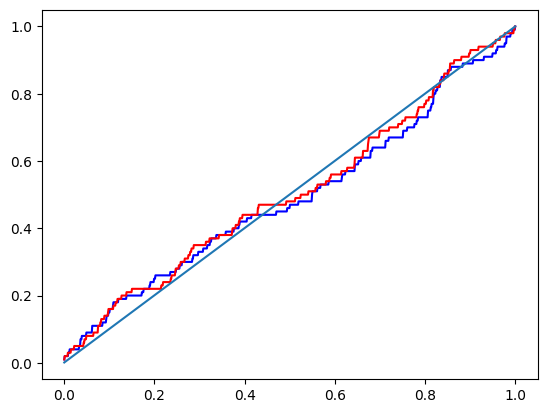

In [35]:
cvm_loaded = np.loadtxt('cvm_values.txt')
ad_loaded = np.loadtxt('ad_values.txt')

def ecdf(x, obs):
    l = np.linspace(min(obs), max(obs), len(obs)*100)
    return(sc.stats.ecdf(obs).cdf.evaluate(x))

def F(x):
    return sc.stats.norm.cdf(x, 0, np.sqrt(1))
def cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F(y[i-1]))**2 for i in range(1, n)]))
def ad_stat(n,x):
    y = np.sort(x)
    return(-n - np.sum([ (2*i-1)/(n) * (np.log(F(y[i-1]))+np.log(1-F(y[n-i])) ) for i in range(1,n)]))
    
N = 100 # размер выборки из пи вэлью
n = 150 # размер выборки по которым буду считать статистики
pval_cvm = [0]*N
pval_ad = [0]*N

for k in range(N):
    x = np.random.normal(8, np.sqrt(8),n)
    pval_cvm[k] = 1- ecdf(cvm_stat(n, x), cvm_loaded)
    pval_ad[k] = 1- ecdf(ad_stat(n, x), ad_loaded)
l = np.linspace(0,1,1000)
plt.plot(l, ecdf(l, pval_cvm), color = "blue")
plt.plot(l, ecdf(l, pval_ad), color = "red")
plt.plot(l, ecdf(l, l))
plt.show() 

In [ ]:
2. Построить графики p-value критериев Колмогорова, хи-квадрат, Крамера-фон Мизеса, Андерсона-
Дарлинга для проверки гипотезы H0 : Xi ∼ N (0, 1) для а) Xi ∼ pN (0, 1) + (1 − p)N (0, 3) (под суммой

имеется ввиду смесь) б) Xi ∼ 0.5N (μ, 1) + 0.5N (−μ, 1), p = 0.9, μ = 0.1. Подобрать n так, чтобы все
критерии были чувствительны к гипотезе (то есть график p-value существенно отличался от биссек-
трисы, но не становился вертикальным). Какой критерий лучше справляется с задачей? Как вы это
определили?

In [8]:
cvm_loaded = np.loadtxt('cvm_values.txt')
ad_loaded = np.loadtxt('ad_values.txt')

def ecdf(x, obs):
    return(sc.stats.ecdf(obs).cdf.evaluate(x))

def F_0(x):
    return sc.stats.norm.cdf(x, 0, np.sqrt(1))
    
def cvm_stat(n, x):
    y = np.sort(x)
    return(1/(12*n)+np.sum([((2*i-1)/(2*n) - F_0(y[i-1]))**2 for i in range(1, n+1)]))
def ad_stat(n,x):
    y = np.sort(x)
    return(-n - np.sum([ (2*i-1)/(n) * (np.log(F_0(y[i-1]))+np.log(1-F_0(y[n-i])) ) for i in range(1,n+1)]))
def ks_stat(n, x):
    y = np.sort(x)
    m1 = np.max( [i/n - F_0(y[i-1])for i in range(1,n+1)] )
    m2 = np.max( [F_0(y[i-1]) - (i-1)/n for i in range(1,n+1)] )
    return( np.sqrt(n)*np.max([m1,m2]) )
def chi2_stat(k, n, x): # k ячеек, n наблюдений, x это выборка
    delta = [ [sc.stats.norm.ppf((i)/k, 0, 1), sc.stats.norm.ppf((i+1)/k, 0, 1) ] for i in range(k)]
    nu = [0]*k
    for j in range(n):
        for i in range(k):
            if x[j]<=delta[i][1] and x[j]>delta[i][0]:
                nu[i]+=1
    return(np.sum ([(nu[i-1] - n/k)**2 / (n/k) for i in range(1,k+1)]) )
    
def generator_a(n, p):
    x = [0]*n
    for k in range(n):
        if np.random.binomial(1, p) == 1:
            x[k] = np.random.normal(0, 1)     
        else:
            x[k] = np.random.normal(0, np.sqrt(3))  
    return x
    
def generator_b(n, mu):
    x = [0]*n
    for k in range(n):
        if np.random.binomial(1, 0.5) == 1:
            x[k] = np.random.normal(mu, 1)
        else:
            x[k] = np.random.normal(-mu, 1)
    return x

p = 0.9
mu = 0.1
N = 100 # размер выборки из пи вэлью
n = 1000 # размер выборки по которым буду считать статистики
k = int(np.ceil(n**(0.2)))

pval_cvm = [0]*N
pval_ad = [0]*N
pval_ks = [0]*N
pval_chi2 = [0]*N


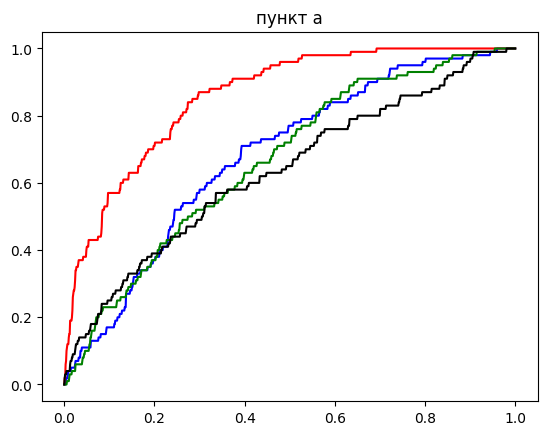

In [11]:
n = 1000
for j in range(N):
    x =  generator_a(n, p)
    #x= np.random.normal(0, 1, size = n)
    pval_cvm[j] = 1 - ecdf(cvm_stat(n, x), cvm_loaded)
    pval_ad[j] = 1 - ecdf(ad_stat(n, x), ad_loaded)
    pval_ks[j] = 1 - sc.stats.kstwobign.cdf(ks_stat(n, x))
    pval_chi2[j] = 1 - sc.stats.chi2.cdf(chi2_stat(k, n, x), k-1)
l = np.linspace(0,1,1000)
plt.title("пункт а")
plt.plot(l, ecdf(l, pval_cvm), color = "blue")
plt.plot(l, ecdf(l, pval_ad), color = "red")
plt.plot(l, ecdf(l, pval_ks), color = "green")
plt.plot(l, ecdf(l, pval_chi2), color = "black")
plt.show()


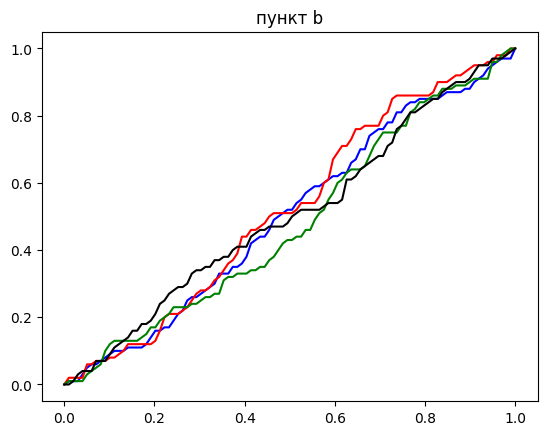

In [12]:
n = 300
mu = 0.1
for j in range(N):
    x =  generator_b(n, mu)
    pval_cvm[j] = 1 - ecdf(cvm_stat(n, x), cvm_loaded)
    pval_ad[j] = 1 - ecdf(ad_stat(n, x), ad_loaded)
    pval_ks[j] = 1 - sc.stats.kstwobign.cdf(ks_stat(n, x))
    pval_chi2[j] = 1 - sc.stats.chi2.cdf(chi2_stat(k, n, x), k-1)
l = np.linspace(0,1,100)
plt.title("пункт b")
plt.plot(l, ecdf(l, pval_cvm), color = "blue")
plt.plot(l, ecdf(l, pval_ad), color = "red")
plt.plot(l, ecdf(l, pval_ks), color = "green")
plt.plot(l, ecdf(l, pval_chi2), color = "black")
plt.show()

In [ ]:
3. * Для предыдущей задачи построить график мощности всех четырех критериев уровня 95% как функ-
ции от параметра p или μ соответственно.

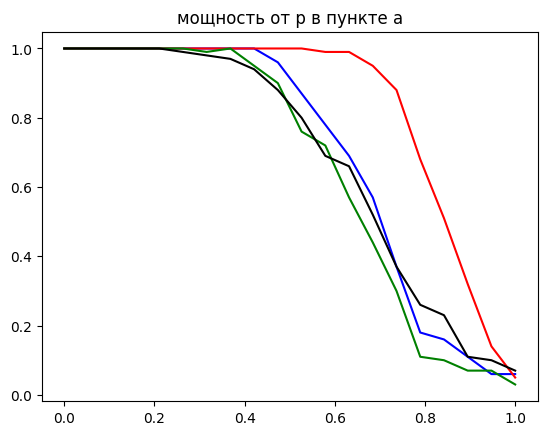

In [13]:
N = 100 # размер выборки из пи вэлью
n = 300 # размер выборки по которым буду считать статистики
k = int(np.ceil(n**(0.2)))
M = 20
p_range = np.linspace(0,1, M)
mu_range= np.linspace(0,1, M)

mosch_cvm = [0]*M
mosch_ad = [0]*M
mosch_chi = [0]*M
mosch_ks = [0]*M

for m in range(M):
    for j in range(N):
        x =  generator_a(n, m/M)
        if (1 - ecdf(cvm_stat(n, x), cvm_loaded) )<0.05:
            mosch_cvm[m] += 1/N
        if  (1 - ecdf(ad_stat(n, x), ad_loaded) )<0.05:
            mosch_ad[m] += 1/N
        if  (1 - sc.stats.kstwobign.cdf(ks_stat(n, x)) )<0.05:
            mosch_ks[m] += 1/N
        if  (1 - sc.stats.chi2.cdf(chi2_stat(k, n, x), k-1) )<0.05:
             mosch_chi[m] += 1/N
plt.title("мощность от р в пункте а")
plt.plot(p_range, mosch_cvm, color = "blue")
plt.plot(p_range, mosch_ad, color = "red")
plt.plot(p_range, mosch_ks, color = "green")
plt.plot(p_range, mosch_chi, color = "black")

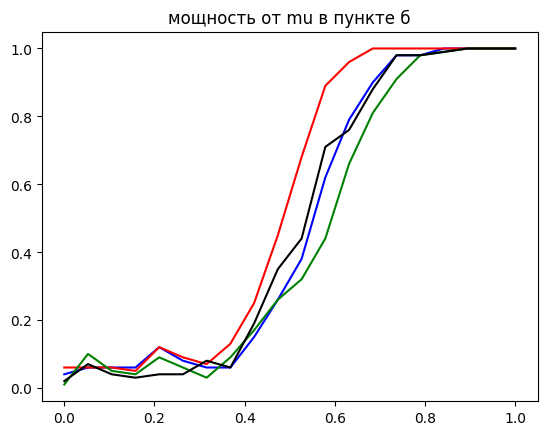

In [9]:
N = 100 # размер выборки из пи вэлью
n = 500 # размер выборки по которым буду считать статистики
k = int(np.ceil(n**(0.2)))
M = 20
p_range = np.linspace(0,1, M)
mu_range= np.linspace(0,1, M)

mosch_cvm = [0]*M
mosch_ad = [0]*M
mosch_chi = [0]*M
mosch_ks = [0]*M

for m in range(M):
    for j in range(N):
        x =  generator_b(n, m/M)
        if (1 - ecdf(cvm_stat(n, x), cvm_loaded) )<0.05:
            mosch_cvm[m] += 1/N
        if  (1 - ecdf(ad_stat(n, x), ad_loaded) )<0.05:
            mosch_ad[m] += 1/N
        if  (1 - sc.stats.kstwobign.cdf(ks_stat(n, x)) )<0.05:
            mosch_ks[m] += 1/N
        if  (1 - sc.stats.chi2.cdf(chi2_stat(k, n, x), k-1) )<0.05:
             mosch_chi[m] += 1/N
plt.title("мощность от mu в пункте б")
plt.plot(p_range, mosch_cvm, color = "blue")
plt.plot(p_range, mosch_ad, color = "red")
plt.plot(p_range, mosch_ks, color = "green")
plt.plot(p_range, mosch_chi, color = "black")